# Kompresja obrazu z użyciem FFT i DCT

**Autor:** Jakub Psarski <br />
**Data:** 14.10.2026

Program wyznacza FFT i DCT obrazu `lena.jpg` (oryginał oraz wersja z szumem), kwantyzuje współczynniki i odtwarza obraz. Jakość rekonstrukcji mierzona jest PSNR względem oryginału.

## Importy i parametry

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

IMG_PATH = Path("lena.jpg")
STEP = 20  # krok kwantyzacji
NOISE_SIGMA = 20  # odchylenie std. szumu
METHOD_NAMES = {
    "f": "FFT",
    "d": "DCT",
}

## Funkcje pomocnicze

In [2]:
# szum gaussowski
def add_noise(image):
    return np.clip(image + np.random.normal(0, NOISE_SIGMA, image.shape), 0, 255)


# transformacja
def transform(method, image):
    if method == "f":
        return np.fft.fft2(image, norm="ortho")
    return cv2.dct(image)


# odwrócenie transformacji
def inverse(method, X):
    if method == "f":
        return np.real(np.fft.ifft2(X, norm="ortho"))
    return cv2.idct(X)


# kwantyzacja (dla FFT osobno Re i Im)
def quantize(X):
    if np.iscomplexobj(X):
        return quantize(X.real) + 1j * quantize(X.imag)
    return np.round(X / STEP) * STEP


# widmo w skali logarytmicznej
def spectrum(method, X):
    if method == "f":
        X = np.fft.fftshift(X)
    return np.log1p(np.abs(X))


# PSNR (Peak Signal-to-Noise Ratio) do porównania obrazów
def psnr(a, b):
    return 10 * np.log10(255**2 / np.mean((a - b) ** 2))


# transformata, kwantyzacja, rekonstrukcja i wykres
def run(method, name, x):
    Xq = quantize(transform(method, x))
    rec = np.clip(inverse(method, Xq), 0, 255)
    nonzero = np.count_nonzero(Xq) / Xq.size * 100
    p_out = psnr(img, rec)
    print(
        f"{METHOD_NAMES[method]}, {name}: non-zero coefficients {nonzero:.2f}%, "
        f"PSNR reconstruction {p_out:.2f} dB"
    )

    plt.figure(figsize=(5, 15))

    plt.subplot(3, 1, 1)
    plt.imshow(x, cmap="gray", vmin=0, vmax=255)
    title = f"{METHOD_NAMES[method]}: {name}" + f", PSNR={psnr(img, x):.2f} dB" if name == "noisy" else ""
    plt.title(title)
    plt.axis("off")

    plt.subplot(3, 1, 2)
    plt.imshow(spectrum(method, Xq), cmap="gray")
    plt.title(f"{METHOD_NAMES[method]} after quantization (step={STEP}), non-zero={nonzero:.2f}%")
    plt.axis("off")

    plt.subplot(3, 1, 3)
    plt.imshow(rec, cmap="gray", vmin=0, vmax=255)
    plt.title(f"reconstruction, PSNR={p_out:.2f} dB")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

## Wczytanie obrazu i dodanie szumu

In [3]:
img = cv2.imread(IMG_PATH, cv2.IMREAD_GRAYSCALE)
img = img[: img.shape[0] // 2 * 2, : img.shape[1] // 2 * 2].astype(np.float64)  # DCT wymaga parzystych wymiarów
noisy = add_noise(img)
print("image size:", img.shape)
print(f"PSNR noisy: {psnr(img, noisy):.2f} dB")

image size: (1230, 1060)
PSNR noisy: 23.03 dB


## FFT – obraz bez szumu

FFT, original: non-zero coefficients 13.61%, PSNR reconstruction 35.44 dB


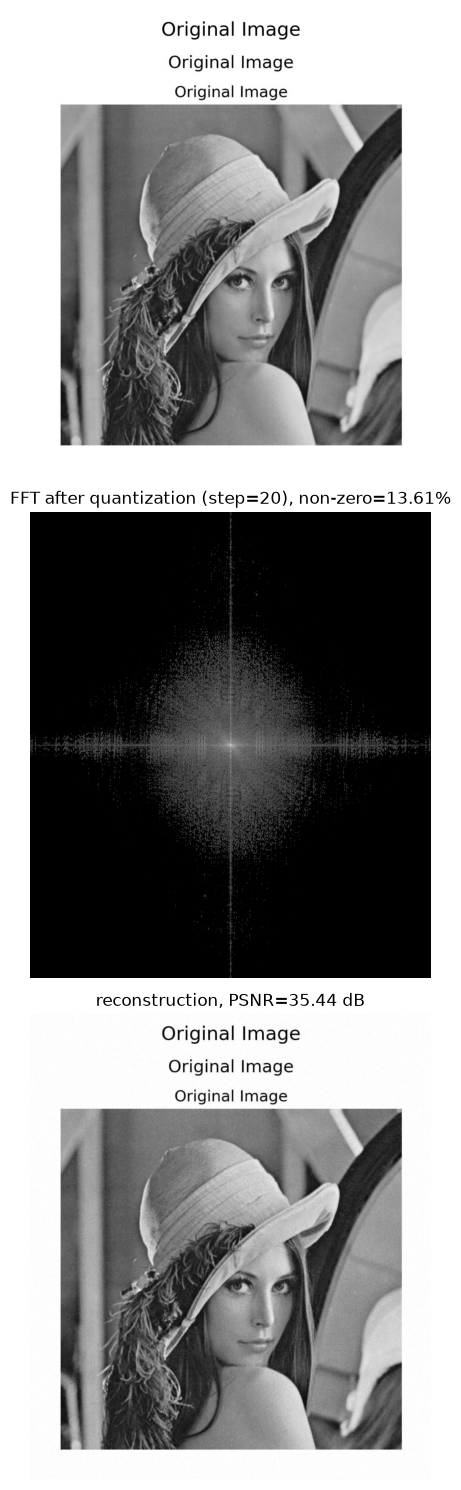

In [4]:
run("f", "original", img)

## FFT – obraz z szumem

FFT, noisy: non-zero coefficients 70.13%, PSNR reconstruction 22.34 dB


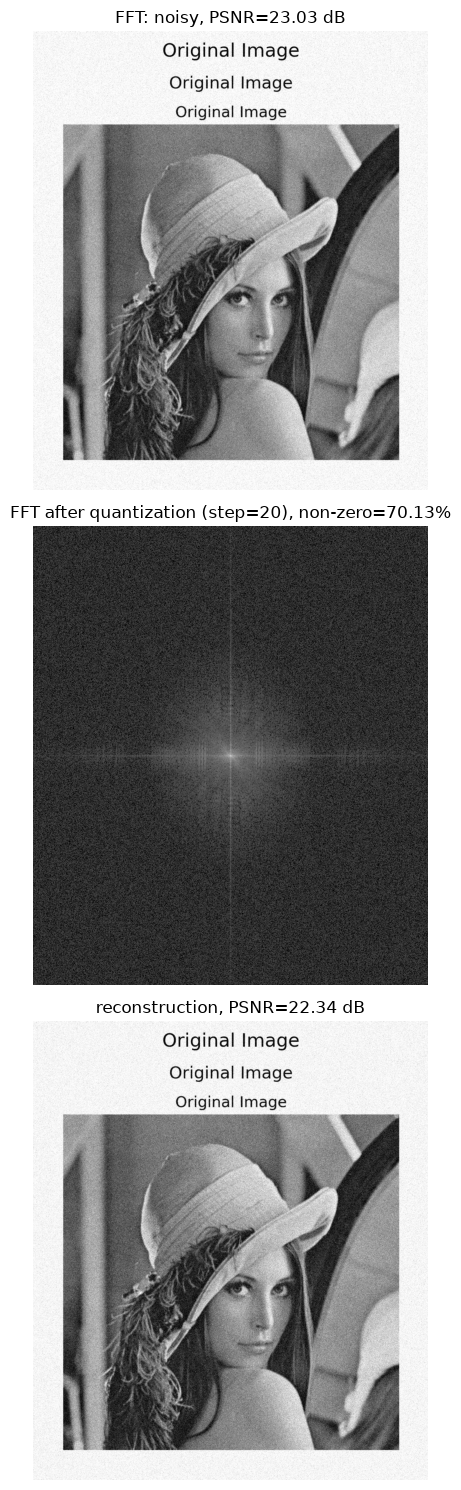

In [5]:
run("f", "noisy", noisy)

## DCT – obraz bez szumu

DCT, original: non-zero coefficients 13.42%, PSNR reconstruction 37.22 dB


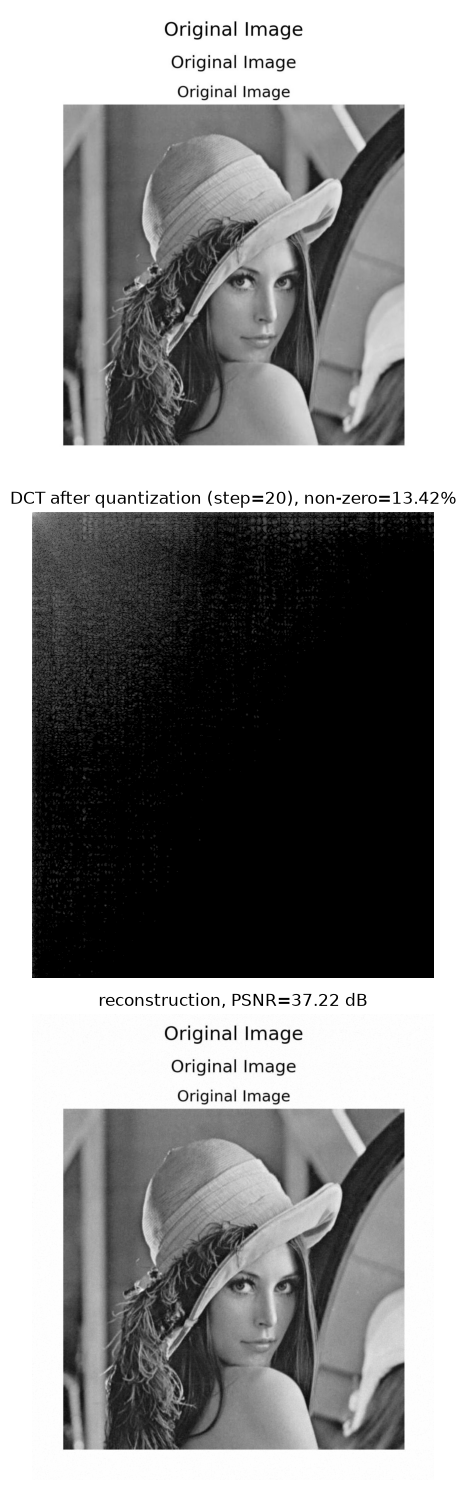

In [6]:
run("d", "original", img)

## DCT – obraz z szumem

DCT, noisy: non-zero coefficients 60.18%, PSNR reconstruction 22.67 dB


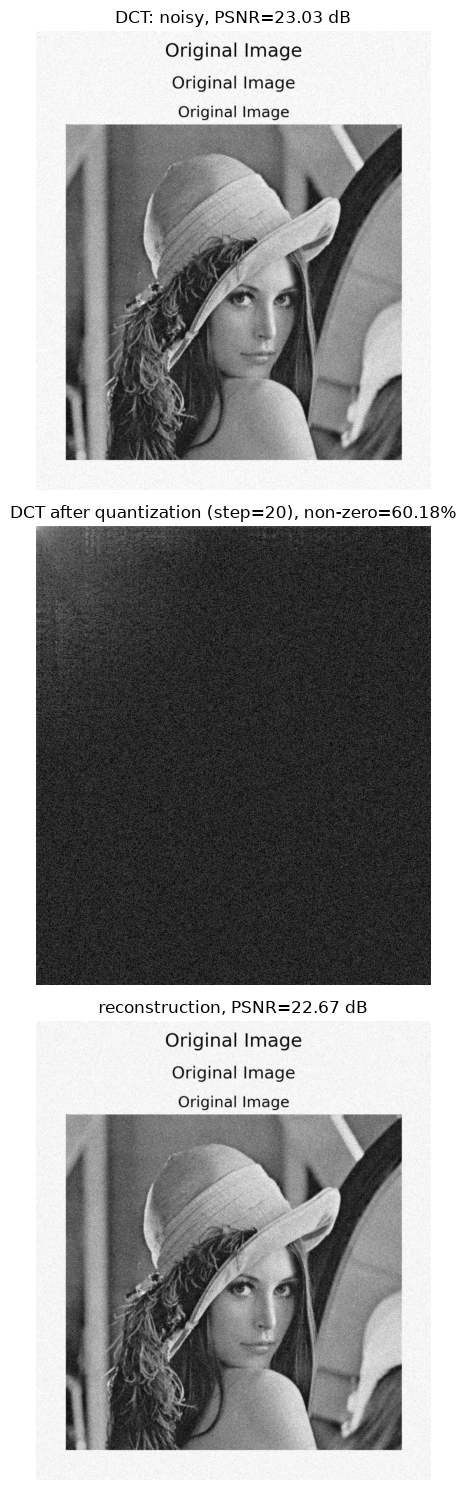

In [7]:
run("d", "noisy", noisy)

## Wnioski

DCT daje lepsze wyniki niż FFT. Przy prawie tej samej liczbie niezerowych współczynników (około 13,5%) obraz odtworzony z DCT jest wyraźnie lepszej jakości (37,2 dB wobec 35,4 dB). Dodanie szumu zwiększa liczbę niezerowych współczynników z około 13% do 60–70%, więc kompresja jest dużo słabsza, a kwantyzacja nie usuwa szumu - jakość po rekonstrukcji jest nawet trochę gorsza niż obrazu zaszumionego przed transformacją.